<a href="https://colab.research.google.com/github/ASAND5/lazy_projects/blob/main/Bore_Doing_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd

import os
for dirname, _, filenames in os.walk('/content/drive/MyDrive/Project at Zindi/Titanic/'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/content/drive/MyDrive/Project at Zindi/Titanic/test.csv
/content/drive/MyDrive/Project at Zindi/Titanic/gender_submission.csv
/content/drive/MyDrive/Project at Zindi/Titanic/train.csv


In [5]:
train_data = pd.read_csv("/content/drive/MyDrive/Project at Zindi/Titanic/train.csv")
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
test_data = pd.read_csv("/content/drive/MyDrive/Project at Zindi/Titanic/test.csv")
test_data.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [7]:
women = train_data.loc[train_data.Sex == 'female']["Survived"]
rate_women = sum(women)/len(women)

print("% of women who survived:", rate_women)

% of women who survived: 0.7420382165605095


In [8]:
men = train_data.loc[train_data.Sex == 'male']["Survived"]
rate_men = sum(men)/len(men)

print("% of men who survived:", rate_men)

% of men who survived: 0.18890814558058924


In [9]:
from sklearn.ensemble import RandomForestClassifier

y = train_data["Survived"]

features = ["Pclass", "Sex", "SibSp", "Parch"]
X = pd.get_dummies(train_data[features])
X_test = pd.get_dummies(test_data[features])

model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=1)
model.fit(X, y)
predictions = model.predict(X_test)

output = pd.DataFrame({'PassengerId': test_data.PassengerId, 'Survived': predictions})
output.to_csv('submission.csv', index=False)
print("Your submission was successfully saved!")

Your submission was successfully saved!


/tmp/ipykernel_4961/890971910.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived', data=submission_df, palette='viridis')


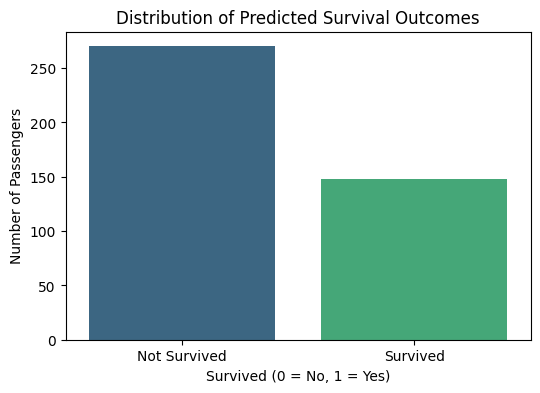

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

submission_df = pd.read_csv('submission.csv')

plt.figure(figsize=(6, 4))
sns.countplot(x='Survived', data=submission_df, palette='viridis')
plt.title('Distribution of Predicted Survival Outcomes')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.xticks([0, 1], ['Not Survived', 'Survived'])
plt.show()

The bar plot above shows the distribution of the model's predictions for survival. We can see the count of passengers predicted to have survived (1) and not survived (0) in the test set.

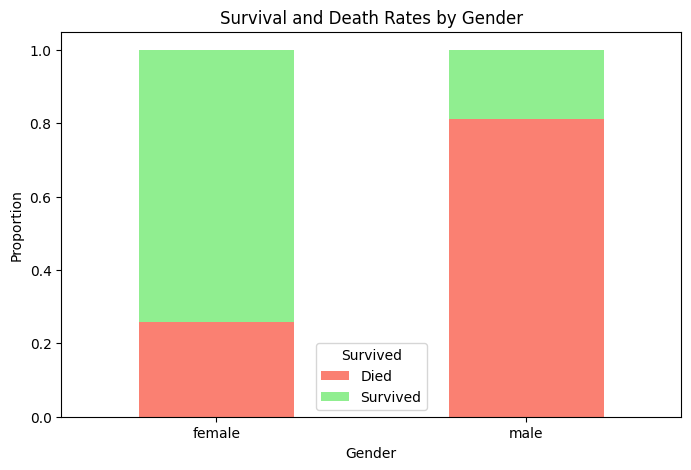

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

survival_by_sex = train_data.groupby('Sex')['Survived'].value_counts(normalize=True).unstack()

survival_by_sex.plot(kind='bar', stacked=True, figsize=(8, 5), color=['salmon', 'lightgreen'])
plt.title('Survival and Death Rates by Gender')
plt.xlabel('Gender')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.legend(title='Survived', labels=['Died', 'Survived'])
plt.show()

This stacked bar chart clearly shows the proportion of men and women who survived versus those who died. As observed earlier, a higher proportion of women survived compared to men.

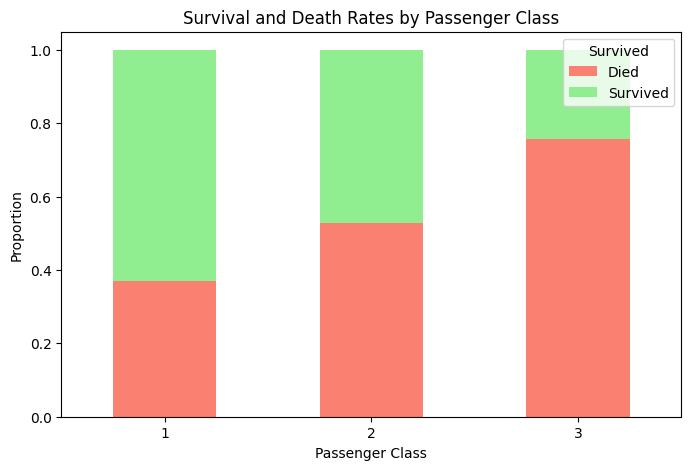

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

survival_by_pclass = train_data.groupby('Pclass')['Survived'].value_counts(normalize=True).unstack()

survival_by_pclass.plot(kind='bar', stacked=True, figsize=(8, 5), color=['salmon', 'lightgreen'])
plt.title('Survival and Death Rates by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.legend(title='Survived', labels=['Died', 'Survived'])
plt.show()

This stacked bar chart illustrates the survival and death rates across different passenger classes. It clearly shows that passengers in higher classes (Class 1) had a significantly higher chance of survival compared to those in lower classes (Class 3).

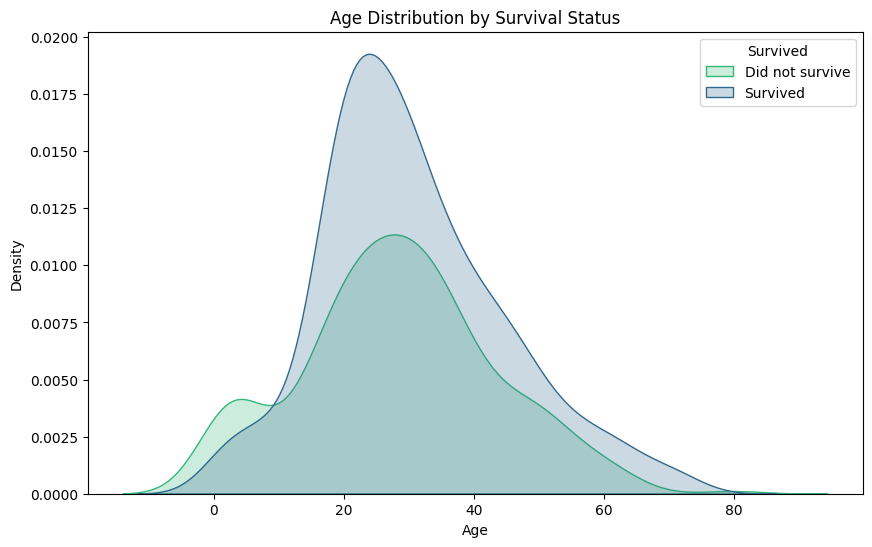

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.kdeplot(data=train_data, x='Age', hue='Survived', fill=True, palette='viridis')
plt.title('Age Distribution by Survival Status')
plt.xlabel('Age')
plt.ylabel('Density')
plt.legend(title='Survived', labels=['Did not survive', 'Survived'])
plt.show()